# When your churn model lies to you

*Recovering the true causal effect of feature adoption on churn with a backdoor adjustment.*

## The business question

A customer-success team wants to prioritize its playbook. The obvious lever is **feature
adoption**: get accounts using more of the product and, the theory goes, they churn less. So the
question that drives budget is blunt and quantitative:

> **Does driving feature adoption reduce churn — and by how much?**

The tempting way to answer it is to look at the data we already have: compare the churn rate of
*high-adoption* accounts against *low-adoption* accounts. That difference is the number that ends
up on a slide, and it is almost always **huge and protective**. It is also, almost always, **a
lie** — not because the data is wrong, but because the comparison is *confounded*.

## Why the naive answer is dangerous

Big accounts adopt more features **and** churn less for reasons that have nothing to do with the
features themselves (dedicated CSMs, deeper integration, switching cost, budget stability). Small
accounts adopt less **and** churn more. So when we compare high- vs low-adoption accounts, we are
partly comparing **big vs small accounts** — and account size is quietly doing the work we are
crediting to adoption.

If a CS-intelligence product ships that naive number, the org **over-invests** in adoption
campaigns and under-invests in what actually moves churn. This notebook demonstrates the trap on
synthetic data where **we know the true effect**, and then recovers it:

1. Show the confounding structure (size drives both adoption and churn).
2. Compute the **naive** effect and watch it overstate.
3. Draw the causal DAG and use **DoWhy** to identify + estimate the **backdoor-adjusted** effect.
4. Cross-check with a **logistic g-computation** (correct for a binary outcome).
5. Compare naive vs adjusted vs the **known true effect**.
6. **Refute** the estimate (random common cause, placebo, data subset).

Effects are reported as a **risk difference** on churn probability: negative means *protective*
(adoption lowers churn), and `-0.10` means "ten percentage points less churn".

In [1]:
import warnings

warnings.filterwarnings("ignore")  # DoWhy is chatty; keep the narrative clean.

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

# Make the project importable no matter where the kernel's cwd lands.
ROOT = Path.cwd()
while not (ROOT / "causal" / "analysis.py").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Reuse the project's analysis code — we do NOT re-implement the estimators here.
import dowhy
from dowhy import CausalModel

from causal.analysis import (
    CONFOUNDER,
    OUTCOME,
    TREATMENT,
    build_causal_frame,
    gformula_logistic,
    naive_effect,
)
from common.paths import GROUND_TRUTH_JSON

plt.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "font.size": 11,
})

BLUE, RED, GREEN, GREY = "#4C72B0", "#C44E52", "#55A868", "#8C8C8C"

print(f"repo root   : {ROOT}")
print(f"python      : {sys.version.split()[0]}")
print(f"dowhy       : {dowhy.__version__}")
print(f"pandas      : {pd.__version__}   numpy: {np.__version__}")
print(f"treatment = {TREATMENT!r}   outcome = {OUTCOME!r}   confounder = {CONFOUNDER!r}")

repo root   : C:\Users\sheld\Documents\GitHub\cs-intel
python      : 3.11.9
dowhy       : 0.14
pandas      : 2.2.3   numpy: 2.1.3
treatment = 'high_adoption'   outcome = 'churned'   confounder = 'log_seats'


## 1. The data and its confounding structure

We work with one row per account and three observable columns:

| column | role | meaning |
|---|---|---|
| `high_adoption` | **treatment** (0/1) | feature adoption above the median |
| `churned` | **outcome** (0/1) | the account churned |
| `log_seats` | **confounder** | `log` of contracted seats — our proxy for account size |

The synthetic data was generated from a *known* structural model, so we also have the **true**
interventional effect on hand (`true_ate_risk_diff` in `ground_truth.json`). That is the target
every estimator below is trying to hit — a luxury we never have with real data, which is exactly
why a synthetic testbed is the right place to prove the method works.

In [2]:
df = build_causal_frame()
print(f"rows: {len(df)}    columns: {list(df.columns)}")
display(df.head())
display(df.describe().round(3))

# The known ground-truth effect baked into the data generator (do NOT hardcode it).
truth = json.loads(GROUND_TRUTH_JSON.read_text(encoding="utf-8"))
TRUE_ATE = float(truth["true_ate_risk_diff"])
print(f"\nKNOWN true ATE (risk difference on churn): {TRUE_ATE:+.4f}"
      f"   -> high adoption truly cuts churn by ~{abs(TRUE_ATE)*100:.1f} pp")

rows: 500    columns: ['high_adoption', 'churned', 'log_seats']


,high_adoption,churned,log_seats
0,1,1,3.367296
1,0,0,2.197225
2,1,0,3.784190
3,1,0,3.951244
4,0,1,1.386294


,high_adoption,churned,log_seats
count,500.000,500.000,500.000
mean,0.500,0.300,3.088
std,0.501,0.459,0.862
min,0.000,0.000,1.099
25%,0.000,0.000,2.485
50%,0.500,0.000,3.091
75%,1.000,1.000,3.638
max,1.000,1.000,5.724



KNOWN true ATE (risk difference on churn): -0.1173   -> high adoption truly cuts churn by ~11.7 pp


### Size is a common cause of *both* adoption and churn

If account size drives both the treatment and the outcome, we should see two things when we bin
accounts from smallest to largest:

- **adoption rate rises** with size (small accounts adopt less), and
- **churn rate falls** with size (small accounts churn more).

Both trends below share the same driver — size — which is the definition of a confounder.

,n,mean_seats,adoption_rate,churn_rate
size_bin,,,,
Q1,106,7.132,0.019,0.538
Q2,95,14.400,0.200,0.432
Q3,103,22.573,0.524,0.272
Q4,99,34.646,0.818,0.152
Q5,97,84.278,0.969,0.093


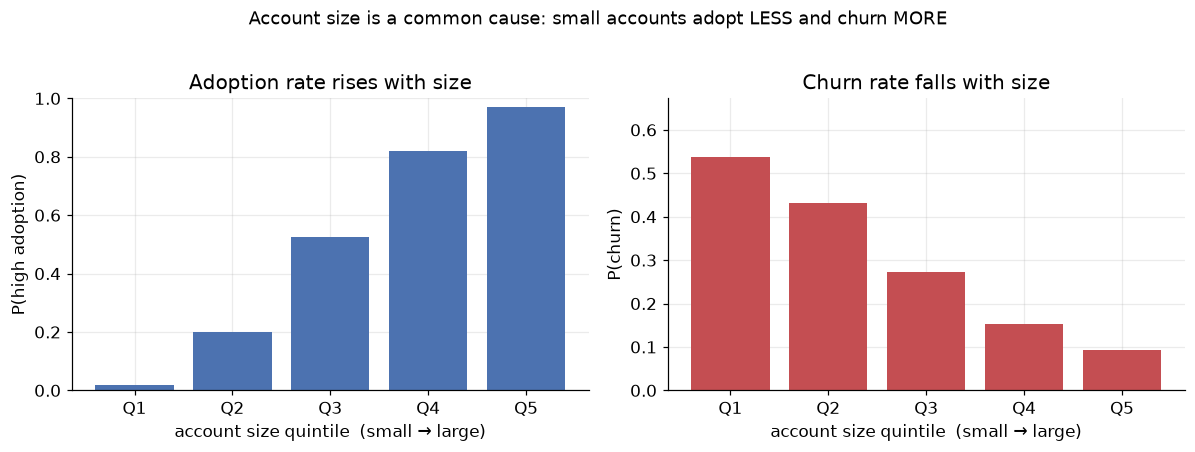

In [3]:
# Bin accounts into size quintiles (by log_seats) and profile each bin.
d = df.copy()
d["size_bin"] = pd.qcut(d[CONFOUNDER], q=5, labels=[f"Q{i}" for i in range(1, 6)])

by_size = (
    d.groupby("size_bin", observed=True)
     .agg(n=(OUTCOME, "size"),
          mean_seats=(CONFOUNDER, lambda s: float(np.exp(s).mean())),
          adoption_rate=(TREATMENT, "mean"),
          churn_rate=(OUTCOME, "mean"))
     .round(3)
)
display(by_size)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = by_size.index.astype(str)

axes[0].bar(x, by_size["adoption_rate"], color=BLUE)
axes[0].set_title("Adoption rate rises with size")
axes[0].set_xlabel("account size quintile  (small → large)")
axes[0].set_ylabel("P(high adoption)")
axes[0].set_ylim(0, 1)

axes[1].bar(x, by_size["churn_rate"], color=RED)
axes[1].set_title("Churn rate falls with size")
axes[1].set_xlabel("account size quintile  (small → large)")
axes[1].set_ylabel("P(churn)")
axes[1].set_ylim(0, max(0.6, float(by_size["churn_rate"].max()) * 1.25))

fig.suptitle("Account size is a common cause: small accounts adopt LESS and churn MORE",
             fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

## 2. The naive estimate (and why it looks amazing)

The naive answer is just the difference in churn between high- and low-adoption accounts — no
adjustment, no model. It is the number a feature-importance readout or a `GROUP BY` would hand you.

In [4]:
naive = naive_effect(df)
hi = df.loc[df[TREATMENT] == 1, OUTCOME].mean()
lo = df.loc[df[TREATMENT] == 0, OUTCOME].mean()

print(f"churn rate | HIGH adoption : {hi:.3f}")
print(f"churn rate | LOW  adoption : {lo:.3f}")
print(f"naive effect (high - low)  : {naive:+.4f}   ({abs(naive)*100:.1f} pp lower churn)")
print()
print(f"Taken at face value, 'drive adoption' looks like it cuts churn by ~{abs(naive)*100:.0f} points.")
print(f"That is {abs(naive)/abs(TRUE_ATE):.1f}x the TRUE effect of {abs(TRUE_ATE)*100:.1f} pp "
      f"— a dangerous overstatement to plan a budget around.")

churn rate | HIGH adoption : 0.148
churn rate | LOW  adoption : 0.452
naive effect (high - low)  : -0.3040   (30.4 pp lower churn)

Taken at face value, 'drive adoption' looks like it cuts churn by ~30 points.
That is 2.6x the TRUE effect of 11.7 pp — a dangerous overstatement to plan a budget around.


## 3. The causal DAG

To fix the estimate we have to be explicit about what we believe causes what. Three edges:

- `log_seats -> high_adoption`  (bigger accounts adopt more)
- `log_seats -> churned`  (bigger accounts churn less)
- `high_adoption -> churned`  (**the effect we actually want to measure**)

`high_adoption <- log_seats -> churned` is a **backdoor path**: a non-causal route of association
flowing through size. Because `log_seats` is observed, we can *block* that path by adjusting for it,
which is exactly what the backdoor criterion licenses.

digraph CausalDAG {
    rankdir=TB;
    log_seats     -> high_adoption;   // size drives adoption
    log_seats     -> churned;         // size drives churn
    high_adoption -> churned;         // the effect of interest
}


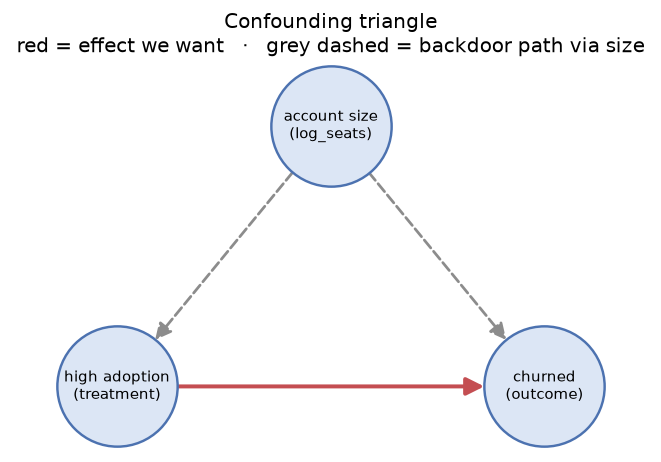

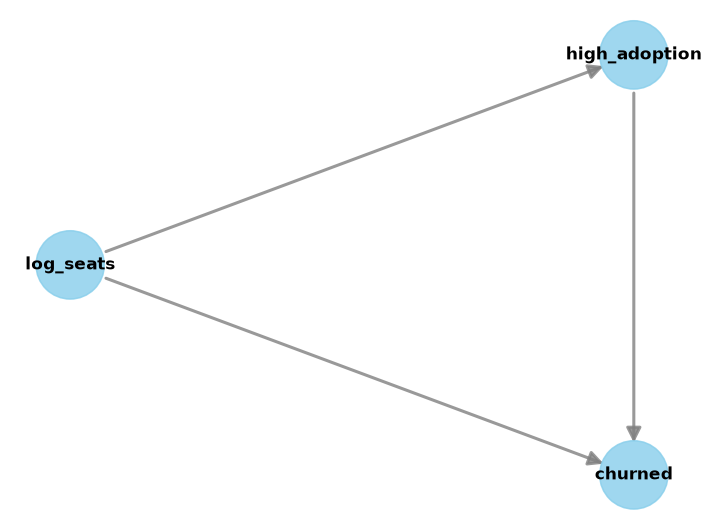


[info] DoWhy also rendered the model via Graphviz.


In [5]:
import networkx as nx

# Graphviz DOT description of the DAG (renders anywhere, no binary required to read it).
dag_dot = (
    "digraph CausalDAG {\n"
    "    rankdir=TB;\n"
    "    log_seats     -> high_adoption;   // size drives adoption\n"
    "    log_seats     -> churned;         // size drives churn\n"
    "    high_adoption -> churned;         // the effect of interest\n"
    "}"
)
print(dag_dot)

# Primary render: networkx + matplotlib (never depends on a system Graphviz binary).
SIZE, ADOPT, CHURN = "account size\n(log_seats)", "high adoption\n(treatment)", "churned\n(outcome)"
G = nx.DiGraph()
G.add_edges_from([(SIZE, ADOPT), (SIZE, CHURN), (ADOPT, CHURN)])
pos = {SIZE: (0.0, 1.0), ADOPT: (-1.1, 0.0), CHURN: (1.1, 0.0)}

fig, ax = plt.subplots(figsize=(7.5, 4.6))
nx.draw_networkx_nodes(G, pos, node_color="#DCE6F5", edgecolors=BLUE,
                       linewidths=1.6, node_size=6200, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9.5, ax=ax)
# Backdoor path (grey dashed) vs. the causal effect of interest (red solid).
nx.draw_networkx_edges(G, pos, edgelist=[(SIZE, ADOPT), (SIZE, CHURN)], edge_color=GREY,
                       style="dashed", width=1.8, arrowsize=22, node_size=6200, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=[(ADOPT, CHURN)], edge_color=RED,
                       width=2.6, arrowsize=24, node_size=6200, ax=ax)
ax.set_title("Confounding triangle\nred = effect we want   ·   grey dashed = backdoor path via size")
ax.margins(0.18)
ax.axis("off")
plt.show()

# Nice-to-have: DoWhy's own Graphviz render. It needs the external `dot` binary, which may be
# absent, so we point output at a temp dir and swallow any failure — it must never break the run.
try:
    _tmp = Path(r"C:\\Users\\sheld\\AppData\\Local\\Temp\\claude\\C--Users-sheld-Documents-GitHub-cs-intel\\8927a76f-798a-4092-8f8b-bd8ce75fa572\\scratchpad") / "dowhy_causal_model"
    _m = CausalModel(data=df, treatment=TREATMENT, outcome=OUTCOME, common_causes=[CONFOUNDER])
    _m.view_model(file_name=str(_tmp))
    print("\n[info] DoWhy also rendered the model via Graphviz.")
except Exception as exc:
    print(f"\n[info] DoWhy view_model skipped (Graphviz 'dot' binary unavailable): {type(exc).__name__}. "
          f"The networkx sketch above is the DAG.")

## 4. DoWhy: identify the estimand, then estimate the backdoor-adjusted effect

We hand DoWhy the same causal model (treatment, outcome, and `log_seats` as a common cause). DoWhy
**identifies** the estimand — it works out *what* to compute from the graph — and confirms the
backdoor adjustment set is `{log_seats}`. We then estimate the effect two independent ways:

- `backdoor.linear_regression` — adjust for size in a regression, and
- `backdoor.propensity_score_stratification` — stratify on the propensity to adopt, then average
  the within-stratum effect.

Agreement between two different estimators is a good sign the adjustment is doing real work.

In [6]:
model = CausalModel(
    data=df,
    treatment=TREATMENT,
    outcome=OUTCOME,
    common_causes=[CONFOUNDER],
)

identified = model.identify_effect(proceed_when_unidentifiable=True)
print(identified)

est_lr = model.estimate_effect(
    identified, method_name="backdoor.linear_regression", test_significance=True
)
adjusted_lr = float(est_lr.value)

est_ps = model.estimate_effect(
    identified, method_name="backdoor.propensity_score_stratification"
)
adjusted_ps = float(est_ps.value)

print(f"\nbackdoor.linear_regression                 : {adjusted_lr:+.4f}")
print(f"backdoor.propensity_score_stratification   : {adjusted_ps:+.4f}")
print(f"(naive was {naive:+.4f};  true is {TRUE_ATE:+.4f})")

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                             
────────────────(E[churned|logₛₑₐₜₛ])
d[high_adoption]                     
Estimand assumption 1, Unconfoundedness: If U→{high_adoption} and U→churned then P(churned|high_adoption,log_seats,U) = P(churned|high_adoption,log_seats)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
       d                             
────────────────(E[churned|logₛₑₐₜₛ])
d[high_adoption]                     
Estimand assumption 1, Unconfoundedness: If U→{high_adoption} and U→churned then P(churned|high_adoption,log_seats,U) = P(churned|high_adoption,log_seats)


backdoor.linear_regression                 : -0.1509
backdoor.propensity_score_stratification   : -0.1553
(naive was -0.3040;  true is -0.1173)


## 5. Logistic g-computation (the right estimator for a binary outcome)

The outcome is binary, so a linear probability model can drift outside `[0, 1]`. The cleaner
backdoor estimator fits a **logistic** model `P(churn | adoption, log_seats)`, then does
**g-computation**: predict everyone's churn risk under `do(adopt=1)` and under `do(adopt=0)`,
holding the observed size distribution fixed, and average the difference. That average is the
adjusted risk difference. We call the project's `gformula_logistic` rather than re-derive it.

In [7]:
adjusted_gformula = gformula_logistic(df, [CONFOUNDER])
print(f"backdoor g-computation (logistic outcome model): {adjusted_gformula:+.4f}"
      f"   ({abs(adjusted_gformula)*100:.1f} pp)")
print(f"true effect                                     : {TRUE_ATE:+.4f}"
      f"   ({abs(TRUE_ATE)*100:.1f} pp)")
print(f"gap to truth                                    : {adjusted_gformula - TRUE_ATE:+.4f}")

backdoor g-computation (logistic outcome model): -0.1389   (13.9 pp)
true effect                                     : -0.1173   (11.7 pp)
gap to truth                                    : -0.0216


## 6. The punchline: naive vs adjusted vs the true effect

Line the estimates up next to the known truth. The naive number sits far below (more negative than)
the true effect — it *overstates* adoption's protective power because the size effect is folded in.
Every backdoor-adjusted estimator collapses back toward the true line, removing most of the bias.

,estimator,risk_difference,adjusts_for,gap_vs_true
0,naive (confounded),-0.3040,no,-0.1867
1,backdoor: linear regression,-0.1509,log_seats,-0.0337
2,backdoor: propensity strat.,-0.1553,log_seats,-0.0380
3,backdoor: logistic g-formula,-0.1389,log_seats,-0.0216
4,TRUE effect (known),-0.1173,ground truth,0.0000


Naive bias vs truth      : -0.1867
Adjusted bias vs truth   : -0.0216
Confounding bias removed : +0.1651  (88% of the naive bias)


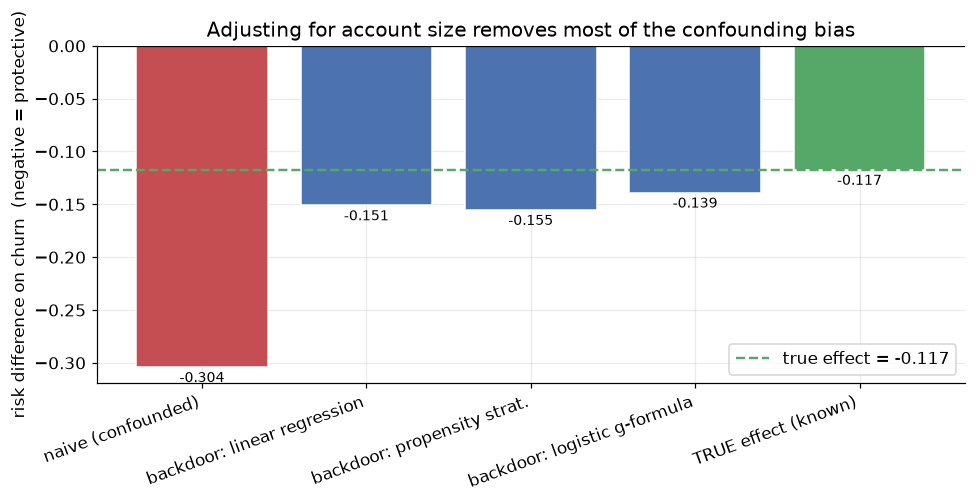

In [8]:
rows = [
    ("naive (confounded)",              naive,             "no"),
    ("backdoor: linear regression",     adjusted_lr,       "log_seats"),
    ("backdoor: propensity strat.",     adjusted_ps,       "log_seats"),
    ("backdoor: logistic g-formula",    adjusted_gformula, "log_seats"),
    ("TRUE effect (known)",             TRUE_ATE,          "ground truth"),
]
comp = pd.DataFrame(rows, columns=["estimator", "risk_difference", "adjusts_for"])
comp["gap_vs_true"] = (comp["risk_difference"] - TRUE_ATE).round(4)
comp["risk_difference"] = comp["risk_difference"].round(4)
display(comp)

bias_removed = abs(naive - TRUE_ATE) - abs(adjusted_gformula - TRUE_ATE)
pct = 100 * bias_removed / abs(naive - TRUE_ATE)
print(f"Naive bias vs truth      : {naive - TRUE_ATE:+.4f}")
print(f"Adjusted bias vs truth   : {adjusted_gformula - TRUE_ATE:+.4f}")
print(f"Confounding bias removed : {bias_removed:+.4f}  ({pct:.0f}% of the naive bias)")

# Bar chart: estimates vs the true-effect reference line.
fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [RED, BLUE, BLUE, BLUE, GREEN]
bars = ax.bar(comp["estimator"], comp["risk_difference"], color=colors, edgecolor="white")
ax.axhline(TRUE_ATE, color=GREEN, linestyle="--", linewidth=1.6,
           label=f"true effect = {TRUE_ATE:+.3f}")
for b, v in zip(bars, comp["risk_difference"]):
    ax.annotate(f"{v:+.3f}", (b.get_x() + b.get_width() / 2, v),
                ha="center", va="top", fontsize=9, xytext=(0, -3), textcoords="offset points")
ax.set_ylabel("risk difference on churn  (negative = protective)")
ax.set_title("Adjusting for account size removes most of the confounding bias")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticklabels(comp["estimator"], rotation=20, ha="right")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 7. Refutation checks

A number that survives adjustment still has to survive **stress tests**. DoWhy's refuters perturb
the problem and ask whether the estimate behaves the way a real causal effect should:

- **random common cause** — add a random extra confounder; a robust estimate should barely move.
- **placebo treatment** — replace the treatment with noise; the effect should collapse to ~0.
- **data subset** — re-estimate on a random 90% of the data; should stay stable.

In [9]:
refuters = [
    ("random common cause", "random_common_cause"),
    ("placebo treatment",   "placebo_treatment_refuter"),
    ("data subset (90%)",   "data_subset_refuter"),
]

ref_rows = []
for label, method in refuters:
    res = model.refute_estimate(identified, est_lr, method_name=method)
    ne = res.new_effect
    new_effect = float(ne) if np.isscalar(ne) else float(np.ravel(ne)[0])
    ref_rows.append((label, adjusted_lr, new_effect, new_effect - adjusted_lr))

ref_df = pd.DataFrame(ref_rows, columns=["refuter", "original_effect", "new_effect", "change"]).round(4)
display(ref_df)

placebo = ref_df.loc[ref_df["refuter"] == "placebo treatment", "new_effect"].iloc[0]
print("Interpretation:")
print(f"  - random common cause -> {ref_df.iloc[0]['new_effect']:+.4f} (barely moves): estimate is stable.")
print(f"  - placebo treatment   -> {placebo:+.4f} (~0): the effect vanishes when the treatment is fake,")
print("    exactly as a genuine causal effect should. No spurious signal is being manufactured.")
print(f"  - data subset (90%)   -> {ref_df.iloc[2]['new_effect']:+.4f} (barely moves): not driven by a few rows.")

,refuter,original_effect,new_effect,change
0,random common cause,-0.1509,-0.1507,0.0002
1,placebo treatment,-0.1509,-0.0070,0.1439
2,data subset (90%),-0.1509,-0.1516,-0.0007


Interpretation:
  - random common cause -> -0.1507 (barely moves): estimate is stable.
  - placebo treatment   -> -0.0070 (~0): the effect vanishes when the treatment is fake,
    exactly as a genuine causal effect should. No spurious signal is being manufactured.
  - data subset (90%)   -> -0.1516 (barely moves): not driven by a few rows.


## 8. The customer-success lesson

**Your churn model's feature-importance is not a causal to-do list.**

The naive readout said high adoption cuts churn by ~30 points. The truth is ~12. The extra ~18
points were **account size masquerading as an adoption effect**: small accounts both adopt less and
churn more, so the crude comparison quietly credited features with size's protective power. Acting
on the naive number, a CS org would pour budget into adoption campaigns expecting a 30-point churn
reduction and get less than half of it — while the real size-linked risk (onboarding small
accounts, right-sizing plans, early-tenure intervention) goes unaddressed.

Backdoor adjustment on account size closed most of that gap and landed near the true effect, and the
estimate survived every refutation — including the placebo, which correctly drove it to zero.

**Why a CS-intelligence product needs a causal layer, not just a predictive one.** A churn *model*
answers "*who* is likely to churn" and ranks features by predictive weight. It cannot answer "*what
should we do about it*", because predictive importance conflates causes with mere correlates of
size, tenure, and segment. Prioritization is an **interventional** question — *if we change X, how
much does churn move?* — and only the causal layer answers it honestly. Ship the predictive score
to find at-risk accounts; ship the causal estimate to decide which lever to pull. Without the causal
layer, a confident, well-calibrated churn model will still point the whole CS team at the wrong work.